# Projet text-minin: données Violences domestiques des femmes

## partie 1 :  Nettoyage

In [46]:
import pandas as pd
import re

def nettoyer_texte(texte):
    """Applique toutes les étapes de nettoyage sur un texte."""
    
    if not isinstance(texte, str) or texte.strip() == "":
        return None

    # ── a. Suppression des liens URL ──────────────────────────────────
    texte = re.sub(r'http\S+|www\.\S+', '', texte)

    # ── b. Suppression des emojis et symboles non textuels ───────────
    texte = re.sub(r'[^\w\s\-\'\,\.\!\?àâäéèêëîïôùûüçœæÀÂÄÉÈÊËÎÏÔÙÛÜÇŒÆ]', ' ', texte)

    # ── c. Suppression des caractères spéciaux ────────────────────────
    texte = re.sub(r'[#@$%&*\^~`<>|\\\/\+\=\[\]\{\}]', ' ', texte)

    # ── d. Conversion en minuscule ────────────────────────────────────
    texte = texte.lower()

    # ── e. Suppression des espaces multiples et lignes vides ──────────
    texte = re.sub(r'\n+', ' ', texte)       # Remplace les sauts de ligne
    texte = re.sub(r'\s+', ' ', texte)       # Remplace les espaces multiples
    texte = texte.strip()                    # Supprime espaces en début/fin

    # Ignorer les textes trop courts après nettoyage
    if len(texte) < 10:
        return None

    return texte


def nettoyer_dataframe(df):
    """Nettoie la colonne texte du DataFrame et retourne les stats."""
    
    print("📊 Statistiques AVANT nettoyage :")
    print(f"   Total lignes        : {len(df)}")
    print(f"   Textes manquants    : {df['texte'].isna().sum()}")
    print(f"   Doublons            : {df.duplicated(subset='texte').sum()}")

    # Appliquer le nettoyage
    df["texte_nettoye"] = df["texte"].apply(nettoyer_texte)

    # Supprimer les lignes dont le texte nettoyé est None ou vide
    df = df.dropna(subset=["texte_nettoye"])
    df = df[df["texte_nettoye"].str.strip() != ""]

    # Supprimer les doublons sur le texte nettoyé
    df = df.drop_duplicates(subset="texte_nettoye")

    print("\n📊 Statistiques APRÈS nettoyage :")
    print(f"   Total lignes        : {len(df)}")
    print(f"   Textes manquants    : {df['texte_nettoye'].isna().sum()}")
    print(f"   Doublons            : {df.duplicated(subset='texte_nettoye').sum()}")

    return df


# ─── EXEMPLE D'APPLICATION ─────────────────────────────────────────────

# Tester sur quelques exemples avant d'appliquer sur tout le dataset
exemples = [
    "Mon mari m'a frappée 😢 #violence @aide https://t.co/xyz   ",
    "My husband HIT me!!!  $%& Check this link http://help.com",
    "   Elle a   fui son   conjoint   violent...   ",
    "💔 J'ai peur de lui tous les jours #aidez-moi !!!",
    "ok"  # Texte trop court → sera supprimé
]

print("🧪 TEST SUR EXEMPLES :\n")
for ex in exemples:
    resultat = nettoyer_texte(ex)
    print(f"  AVANT  : {ex}")
    print(f"  APRÈS  : {resultat}")
    print()

# ─── APPLICATION SUR LE DATASET RÉEL ──────────────────────────────────

print("\n📂 Chargement des données...\n")
df = pd.read_csv("reddit_commentaires.csv", encoding="utf-8-sig")

df = nettoyer_dataframe(df)

# Sauvegarder
df.to_csv("nettoyage/reddit_commentaires_nettoyes.csv", index=False, encoding="utf-8-sig")

# Sauvegarder séparément par langue
df[df["langue"] == "français"].to_csv("nettoyage/reddit_nettoyes_fr.csv", index=False, encoding="utf-8-sig")
df[df["langue"] == "anglais"].to_csv("nettoyage/reddit_nettoyes_en.csv", index=False, encoding="utf-8-sig")

print(f"\n✅ Nettoyage terminé !")
print(f"   Fichier global  : reddit_commentaires_nettoyes.csv")
print(f"   Fichier FR      : reddit_nettoyes_fr.csv")
print(f"   Fichier EN      : reddit_nettoyes_en.csv")


🧪 TEST SUR EXEMPLES :

  AVANT  : Mon mari m'a frappée 😢 #violence @aide https://t.co/xyz   
  APRÈS  : mon mari m'a frappée violence aide

  AVANT  : My husband HIT me!!!  $%& Check this link http://help.com
  APRÈS  : my husband hit me!!! check this link

  AVANT  :    Elle a   fui son   conjoint   violent...   
  APRÈS  : elle a fui son conjoint violent...

  AVANT  : 💔 J'ai peur de lui tous les jours #aidez-moi !!!
  APRÈS  : j'ai peur de lui tous les jours aidez-moi !!!

  AVANT  : ok
  APRÈS  : None


📂 Chargement des données...

📊 Statistiques AVANT nettoyage :
   Total lignes        : 3394
   Textes manquants    : 0
   Doublons            : 79

📊 Statistiques APRÈS nettoyage :
   Total lignes        : 3242
   Textes manquants    : 0
   Doublons            : 0

✅ Nettoyage terminé !
   Fichier global  : reddit_commentaires_nettoyes.csv
   Fichier FR      : reddit_nettoyes_fr.csv
   Fichier EN      : reddit_nettoyes_en.csv


In [47]:
print(df.head())

  commentaire_id  post_id                                         post_titre  \
0        obe0lke  1ryfblu  est-ce que je réessaie ou est-ce que je le lai...   
1        obeq1rw  1ryfblu  est-ce que je réessaie ou est-ce que je le lai...   
2        obesov0  1ryfblu  est-ce que je réessaie ou est-ce que je le lai...   
3        ober2lx  1ryfblu  est-ce que je réessaie ou est-ce que je le lai...   
4        obg10gb  1ryfblu  est-ce que je réessaie ou est-ce que je le lai...   

  subreddit    langue                                              texte  \
0    AskMec  français  Votre publication n'apparaîtra pas immédiateme...   
1    AskMec  français  Il souffle le chaud et le froid, tu danses.\n\...   
2    AskMec  français  Pas mec ici.\n\n\nDésolée mais ton gars se fou...   
3    AskMec  français  sans vouloir être pessimiste, si il dit qu'il ...   
4    AskMec  français  Love bombing classique,  c'est un cas d'école ...   

   score                 date  \
0      1  2026-03-19 22:58:03

## Partie 2 Prétraitement 
> Tokenisation
> StopWord
> Stemming 
> Lematisation


### 2.1 Intaller les dépendances et importer les librairies 

In [48]:
# Installer les librairies nécessaires
!pip install spacy nltk pandas

# Télécharger les modèles de langue spaCy
!python -m spacy download fr_core_news_sm   # Modèle français
!python -m spacy download en_core_web_sm    # Modèle anglais

print('✅ Installation terminée')


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 1.7 MB/s  0:00:09m0:00:0100:01

[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')
     ━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/12.8 MB 617.3 kB/s eta 0:00:20^C
✅ Installation terminée


In [ ]:
import pandas as pd
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
import warnings
warnings.filterwarnings('ignore')

# Télécharger les ressources NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Charger les modèles spaCy
nlp_fr = spacy.load('fr_core_news_sm')   # Modèle français 
nlp_en = spacy.load('en_core_web_sm')    # Modèle anglais

print('✅ Librairies et modèles chargés avec succès')

[nltk_data] Downloading package punkt to /Users/nafy/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/nafy/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/nafy/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


✅ Librairies et modèles chargés avec succès


### 2.2 Charger le fichier nettoyé 

In [ ]:
df = pd.read_csv('nettoyage/reddit_commentaires_nettoyes.csv', encoding='utf-8-sig')

# On travaille sur la colonne texte_nettoye
df = df.dropna(subset=['texte_nettoye'])

print(f'📊 Dataset chargé : {len(df)} commentaires')
print(f'   Langue FR : {len(df[df["langue"] == "français"])}')
print(f'   Langue EN : {len(df[df["langue"] == "anglais"])}')
df[['langue', 'texte_nettoye']].head()

📊 Dataset chargé : 3242 commentaires
   Langue FR : 1607
   Langue EN : 1635


,langue,texte_nettoye
0,français,votre publication n'apparaîtra pas immédiateme...
1,français,"il souffle le chaud et le froid, tu danses. so..."
2,français,pas mec ici. désolée mais ton gars se fout de ...
3,français,"sans vouloir être pessimiste, si il dit qu'il ..."
4,français,"love bombing classique, c'est un cas d'école l..."


### 2.3  Définition des stop words (FR + EN )


In [160]:
# Stopwords NLTK
stop_fr = set(stopwords.words('french'))
stop_en = set(stopwords.words('english'))

stop_custom_fr = {
    # Verbes génériques
    "pouvoir", "faire", "dire", "falloir", "aller", "vouloir", "savoir",
    "voir", "venir", "prendre", "donner", "mettre", "passer", "rendre", "peut", "cas", "doit", "avant", "cela",
    "tenir", "porter", "trouver", "sembler", "parler", "penser", "croire", "être", "par",
    "sentir", "rester", "partir", "arriver", "demander", "aimer", "laisser", "car","elle", "doit",
    # Adjectifs / adverbes génériques
    "tout", "bon", "bien", "vrai", "grand", "même", "autre", "plus",
    "très", "aussi", "encore", "toujours", "jamais", "souvent", "peu",
    "beaucoup", "trop", "vraiment", "déjà", "alors", "quand", "comme",
    "chose", "fois", "an", "jour", "rien", "personne", "temps",
    # Autres
    "ça", "là", "ca", "si", "être", "avoir", "fait", "tout", "sans", "auquel",
    # Toutes les formes de "pouvoir"
    "peux", "peut", "peuvent", "pouvez", "pouvons", "pouvait", "pouvaient",
    "pourra", "pourrai", "pourrais", "pourrait", "pourront", "pouvoir", "pu",
    # Toutes les formes de "faire"
    "fait", "fais", "faite", "faites", "faits", "faire", "faisait", "faisais",
    "ferai", "ferais", "ferait", "feront", "feras",
    # Toutes les formes de "dire"
    "dit", "dis", "dire", "disait", "disais", "diras", "dirait", "diront",
    # Toutes les formes de "aller"
    "vais", "vas", "allait", "allais", "aller", "allé", "allée", "allons",
    "irai", "irais", "irait", "iront",
    # Toutes les formes de "falloir"
    "faut", "fallait", "faudra", "faudrait", "falloir", "fallu",
    # Toutes les formes de "vouloir"
    "veux", "veut", "veulent", "voulez", "voulons", "voulait", "voulais",
    "voudra", "voudrais", "voudrait", "voudront", "vouloir", "voulu",
    # Toutes les formes de "voir"
    "vois", "voit", "voient", "voyez", "voyons", "voyait", "voyais",
    "verra", "verrais", "verrait", "verront", "voir", "vu",
    # Toutes les formes de "venir"
    "viens", "vient", "viennent", "venez", "venons", "venait", "venais",
    "viendra", "viendrais", "viendrait", "viendront", "venir", "venu",
    # Mots génériques
    "tout", "tous", "toute", "toutes", "bien", "très", "aussi", "encore",
    "toujours", "jamais", "souvent", "peu", "beaucoup", "trop", "vraiment",
    "déjà", "alors", "quand", "comme", "même", "autre", "autres",
    "chose", "choses", "fois", "jour", "jours", "rien", "temps",
    "bon", "bonne", "bons", "bonnes", "grand", "grande", "grands",
    "ça", "cela", "ceci", "là", "ici", "car", "donc", "mais", "sinon",
    "ainsi", "après", "avant", "pendant", "depuis", "sans", "sous",
    "plus", "moins", "entre", "vers", "chez", "dont", "lors", "the", "cette",
}

stop_custom_en = {
    # Generic verbs
    "get", "make", "say", "know", "want", "go", "come", "take", "give", "the"
    "see", "think", "look", "feel", "put", "keep", "let", "begin", "show",
    "hear", "try", "call", "ask", "need", "seem", "turn", "tell", "use",
    # Generic words
    "one", "time", "way", "thing", "man", "woman", "people", "year",
    "day", "much", "many", "even", "still", "back", "also", "just",
    "really", "always", "never", "well", "good", "bad", "like", "comment", "work",
    "would", "could", "might", "going", "and", "post",
    # All forms of "get"
    "get", "gets", "got", "getting", "gotten",
    # All forms of "make"
    "make", "makes", "made", "making",
    # All forms of "go"
    "go", "goes", "went", "going", "gone",
    # All forms of "know"
    "know", "knows", "knew", "knowing", "known",
    # All forms of "think"
    "think", "thinks", "thought", "thinking",
    # All forms of "say"
    "say", "says", "said", "saying",
    # All forms of "want"
    "want", "wants", "wanted", "wanting",
    # All forms of "come"
    "come", "comes", "came", "coming",
    # All forms of "take"
    "take", "takes", "took", "taken", "taking",
    # All forms of "see"
    "see", "sees", "saw", "seen", "seeing",
    # All forms of "give"
    "give", "gives", "gave", "given", "giving",
    # All forms of "look"
    "look", "looks", "looked", "looking",
    # All forms of "feel"
    "feel", "feels", "felt", "feeling",
    # All forms of "need"
    "need", "needs", "needed", "needing", "please", "question",
    # Generic words
    "one", "two", "time", "times", "way", "ways", "thing", "things",
    "people", "year", "years", "day", "days", "man", "men", "woman", "women",
    "much", "many", "even", "still", "back", "also", "just", "really",
    "always", "never", "well", "good", "bad", "like", "would", "could",
    "might", "going", "every", "some", "such", "than", "then", "when",
    "that", "this", "these", "those", "they", "them", "their", "there",
    "with", "from", "have", "been", "will", "about", "into", "than", "well",
}

stop_fr.update(stop_custom_fr)
stop_en.update(stop_custom_en)

print(f'✅ Stopwords FR : {len(stop_fr)} mots')
print(f'✅ Stopwords EN : {len(stop_en)} mots')
print(f'\n📋 Exemples FR : {list(stop_fr)[:10]}')
print(f'📋 Exemples EN : {list(stop_en)[:10]}')

✅ Stopwords FR : 338 mots
✅ Stopwords EN : 313 mots

📋 Exemples FR : ['ca', 'aurions', 'venons', 'sous', 'au', 'aie', 'été', 'étiez', 'et', 'les']
📋 Exemples EN : ['in', 'into', 'women', 'did', 'against', 'needing', 'some', 'back', 'itself', 'until']


## 2.4 ✂️ Etape 1 :  Tokenisation
> Découper chaque commentaire en liste de mots (tokens)

In [161]:
def tokeniser(texte, langue):
    """
    Tokenise un texte selon sa langue.
    Retourne une liste de tokens filtrés :
    - Uniquement les mots alphabétiques
    - Entre 3 et 15 caractères
    """
    if not isinstance(texte, str):
        return []

    # Tokenisation avec NLTK
    lang_nltk = 'french' if langue == 'français' else 'english'
    tokens = word_tokenize(texte, language=lang_nltk)

    # Filtrage : alphabétique + longueur entre 3 et 15 caractères
    tokens = [t for t in tokens if t.isalpha() and 3 <= len(t) <= 15]

    return tokens


# Appliquer la tokenisation
df['tokens'] = df.apply(
    lambda row: tokeniser(row['texte_nettoye'], row['langue']), axis=1
)

print('✅ Tokenisation effectuée')
print('\n🔍 Exemple :')
exemple = df[df['langue'] == 'français'].iloc[0]
print(f'  Texte   : {exemple["texte_nettoye"][:80]}...')
print(f'  Tokens  : {exemple["tokens"][:10]}')

✅ Tokenisation effectuée

🔍 Exemple :
  Texte   : votre publication n'apparaîtra pas immédiatement car elle doit être revue par un...
  Tokens  : ['votre', 'publication', 'pas', 'immédiatement', 'car', 'elle', 'doit', 'être', 'revue', 'par']


### 2.5  🚫  Etape 2 : Suppression des stopwords ou mots vides
> Retirer les mots fréquents sans valeur sémantique (le, de, et, the, is...)

In [162]:
def supprimer_stopwords(tokens, langue):
    """
    Supprime les stopwords d'une liste de tokens selon la langue.
    """
    stops = stop_fr if langue == 'français' else stop_en
    return [t for t in tokens if t.lower() not in stops]


# Appliquer la suppression des stopwords
df['tokens_sans_stop'] = df.apply(
    lambda row: supprimer_stopwords(row['tokens'], row['langue']), axis=1
)

print('✅ Suppression des stopwords effectuée')
print('\n🔍 Comparaison :')
exemple = df[df['langue'] == 'français'].iloc[0]
print(f'  Tokens avec stops    : {exemple["tokens"][:10]}')
print(f'  Tokens sans stops    : {exemple["tokens_sans_stop"][:10]}')
print(f'  Mots supprimés       : {len(exemple["tokens"]) - len(exemple["tokens_sans_stop"])}')

✅ Suppression des stopwords effectuée

🔍 Comparaison :
  Tokens avec stops    : ['votre', 'publication', 'pas', 'immédiatement', 'car', 'elle', 'doit', 'être', 'revue', 'par']
  Tokens sans stops    : ['publication', 'immédiatement', 'revue', 'modérateur', 'publiée', 'refus', 'recevrez', 'raison', 'lire', 'règles']
  Mots supprimés       : 26


### 2.6  Lemmatisation   
> Ramener chaque mot à sa forme de base  
> Ex : `marchait` → `marcher` | `victimes` → `victime`


In [163]:
def lemmatiser(tokens, langue):
    """
    Lemmatise une liste de tokens avec spaCy.
    Retourne une liste de lemmes en minuscule.
    """
    if not tokens:
        return []

    nlp = nlp_fr if langue == 'français' else nlp_en

    # Joindre les tokens en texte pour spaCy
    texte = ' '.join(tokens)
    doc = nlp(texte)

    # Extraire les lemmes (en minuscule, alphabétiques uniquement)
    lemmes = [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and len(token.lemma_) >= 3
    ]

    return lemmes


# Appliquer la lemmatisation sur les tokens sans stopwords
print('⏳ Lemmatisation en cours (peut prendre quelques minutes)...')

df['lemmes'] = df.apply(
    lambda row: lemmatiser(row['tokens_sans_stop'], row['langue']), axis=1
)

print('✅ Lemmatisation effectuée')
print('\n🔍 Exemple :')
exemple = df[df['langue'] == 'français'].iloc[0]
print(f'  Tokens sans stops : {exemple["tokens_sans_stop"][:8]}')
print(f'  Lemmes            : {exemple["lemmes"][:8]}')

⏳ Lemmatisation en cours (peut prendre quelques minutes)...
✅ Lemmatisation effectuée

🔍 Exemple :
  Tokens sans stops : ['publication', 'immédiatement', 'revue', 'modérateur', 'publiée', 'refus', 'recevrez', 'raison']
  Lemmes            : ['publication', 'immédiatement', 'revue', 'modérateur', 'publier', 'refus', 'recevoir', 'raison']


### 2.7 Stemming
> Réduire les mots à leur racine (plus agressif que la lemmatisation)  
> Ex : `violences` → `violen` | `abusive` → `abus`


In [164]:
# Initialiser les stemmers
stemmer_fr = SnowballStemmer('french')
stemmer_en = SnowballStemmer('english')


def stemmer(tokens, langue):
    """
    Applique le stemming sur une liste de tokens.
    Retourne une liste de racines.
    """
    if not tokens:
        return []

    stm = stemmer_fr if langue == 'français' else stemmer_en
    return [stm.stem(token) for token in tokens]


# Appliquer le stemming sur les tokens sans stopwords
df['stems'] = df.apply(
    lambda row: stemmer(row['tokens_sans_stop'], row['langue']), axis=1
)

print('✅ Stemming effectué')
print('\n🔍 Exemple :')
exemple = df[df['langue'] == 'français'].iloc[0]
print(f'  Tokens sans stops : {exemple["tokens_sans_stop"][:8]}')
print(f'  Stems             : {exemple["stems"][:8]}')

✅ Stemming effectué

🔍 Exemple :
  Tokens sans stops : ['publication', 'immédiatement', 'revue', 'modérateur', 'publiée', 'refus', 'recevrez', 'raison']
  Stems             : ['publiqu', 'immédiat', 'revu', 'moder', 'publi', 'refus', 'recevr', 'raison']


### 2.8  🔍  Comparaison complète des étapes
> Visualiser la transformation à chaque étape sur un même exemple

In [165]:
print('=' * 65)
print('📊 RÉSUMÉ DES TRANSFORMATIONS NLP')
print('=' * 65)

for langue in ['français', 'anglais']:
    ex = df[df['langue'] == langue].iloc[0]
    print(f'\n🌐 Langue : {langue.upper()}')
    print(f'  Texte brut       : {str(ex["texte_nettoye"])[:70]}...')
    print(f'  Tokens           : {ex["tokens"][:7]}')
    print(f'  Sans stopwords   : {ex["tokens_sans_stop"][:7]}')
    print(f'  Lemmes (spaCy)   : {ex["lemmes"][:7]}')
    print(f'  Stems  (NLTK)    : {ex["stems"][:7]}')
    print('-' * 65)

📊 RÉSUMÉ DES TRANSFORMATIONS NLP

🌐 Langue : FRANÇAIS
  Texte brut       : votre publication n'apparaîtra pas immédiatement car elle doit être re...
  Tokens           : ['votre', 'publication', 'pas', 'immédiatement', 'car', 'elle', 'doit']
  Sans stopwords   : ['publication', 'immédiatement', 'revue', 'modérateur', 'publiée', 'refus', 'recevrez']
  Lemmes (spaCy)   : ['publication', 'immédiatement', 'revue', 'modérateur', 'publier', 'refus', 'recevoir']
  Stems  (NLTK)    : ['publiqu', 'immédiat', 'revu', 'moder', 'publi', 'refus', 'recevr']
-----------------------------------------------------------------

🌐 Langue : ANGLAIS
  Texte brut       : hi! welcome to r essays- we've been getting reports of scammers privat...
  Tokens           : ['welcome', 'been', 'getting', 'reports', 'scammers', 'privately', 'messaging']
  Sans stopwords   : ['welcome', 'reports', 'scammers', 'privately', 'messaging', 'users', 'offering']
  Lemmes (spaCy)   : ['welcome', 'report', 'scammer', 'privately'

## 2.9 📊  Statistiques globales

In [166]:
df['nb_tokens']     = df['tokens'].apply(len)
df['nb_sans_stop']  = df['tokens_sans_stop'].apply(len)
df['nb_lemmes']     = df['lemmes'].apply(len)
df['nb_stems']      = df['stems'].apply(len)

stats = df.groupby('langue')[[
    'nb_tokens', 'nb_sans_stop', 'nb_lemmes', 'nb_stems'
]].mean().round(1)

stats.columns = [
    'Moy. tokens', 'Moy. sans stopwords',
    'Moy. lemmes', 'Moy. stems'
]

print('📊 Nombre moyen de mots par étape et par langue :')
stats

📊 Nombre moyen de mots par étape et par langue :


,Moy. tokens,Moy. sans stopwords,Moy. lemmes,Moy. stems
langue,,,,
anglais,46.6,23.1,23.0,23.1
français,54.7,29.9,29.7,29.9


### 2.10 💾 Sauvegarde du dataset prétraité

In [167]:
# Convertir les listes en chaînes pour la sauvegarde CSV
df['tokens_str']          = df['tokens'].apply(lambda x: ' | '.join(x))
df['tokens_sans_stop_str']= df['tokens_sans_stop'].apply(lambda x: ' | '.join(x))
df['lemmes_str']          = df['lemmes'].apply(lambda x: ' | '.join(x))
df['stems_str']           = df['stems'].apply(lambda x: ' | '.join(x))

# Colonnes à conserver
colonnes = [
    'commentaire_id', 'subreddit', 'langue',
    'texte_nettoye', 'date', 'score',
    'tokens_str', 'tokens_sans_stop_str',
    'lemmes_str', 'stems_str'
]
colonnes_existantes = [c for c in colonnes if c in df.columns]

df[colonnes_existantes].to_csv(
    'preprocessed/reddit_commentaires_preprocessed.csv',
    index=False,
    encoding='utf-8-sig'
)

print('✅ Fichier sauvegardé : preprocessed/reddit_commentaires_preprocessed.csv')
print(f'   Lignes  : {len(df)}')
print(f'   Colonnes: {colonnes_existantes}')

✅ Fichier sauvegardé : preprocessed/reddit_commentaires_preprocessed.csv
   Lignes  : 3242
   Colonnes: ['commentaire_id', 'subreddit', 'langue', 'texte_nettoye', 'date', 'score', 'tokens_str', 'tokens_sans_stop_str', 'lemmes_str', 'stems_str']


## Partie 3 : Analyse et visualisation  

### Importer les dépendances et les librairies

In [59]:
!pip install pandas matplotlib seaborn wordcloud textblob gensim pyldavis scikit-learn
!pip install transformers torch  # Pour l'analyse de sentiments avancée
print('✅ Installation terminée')


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
✅ Installation terminée


In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import warnings
warnings.filterwarnings('ignore')

# Style global des graphiques
plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : 'white',
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.grid'        : True,
    'grid.alpha'       : 0.3,
    'font.family'      : 'sans-serif',
    'font.size'        : 11
})

COLORS = {
    'fr'      : '#534AB7',
    'en'      : '#3266ad',
    'positif' : '#3a9e6e',
    'negatif' : '#c94040',
    'neutre'  : '#73726c'
}

print('✅ Librairies importées avec succès')

✅ Librairies importées avec succès


### 📂 3.1 Chargement du dataset prétraité

In [168]:
df = pd.read_csv('preprocessed/reddit_commentaires_preprocessed.csv', encoding='utf-8-sig')

# Convertir les colonnes de tokens (stockées en string) en listes
df['lemmes_list'] = df['lemmes_str'].dropna().apply(lambda x: x.split(' | '))
df['date']        = pd.to_datetime(df['date'], errors='coerce') 

df_fr = df[df['langue'] == 'français'].copy()
df_en = df[df['langue'] == 'anglais'].copy()

print(f'📊 Dataset chargé : {len(df)} commentaires')
print(f'   FR : {len(df_fr)} | EN : {len(df_en)}')
df.head(3) 

📊 Dataset chargé : 3242 commentaires
   FR : 1607 | EN : 1635


,commentaire_id,subreddit,langue,texte_nettoye,date,score,tokens_str,tokens_sans_stop_str,lemmes_str,stems_str,lemmes_list
0,obe0lke,AskMec,français,votre publication n'apparaîtra pas immédiateme...,2026-03-19 22:58:03,1,votre | publication | pas | immédiatement | ca...,publication | immédiatement | revue | modérate...,publication | immédiatement | revue | modérate...,publiqu | immédiat | revu | moder | publi | re...,"[publication, immédiatement, revue, modérateur..."
1,obeq1rw,AskMec,français,"il souffle le chaud et le froid, tu danses. so...",2026-03-20 01:20:06,46,souffle | chaud | froid | danses | soit | est ...,souffle | chaud | froid | danses | réellement ...,souffle | chaud | froid | danse | réellement |...,souffl | chaud | froid | dans | réel | traumat...,"[souffle, chaud, froid, danse, réellement, tra..."
2,obesov0,AskMec,français,pas mec ici. désolée mais ton gars se fout de ...,2026-03-20 01:35:33,25,pas | mec | ici | désolée | mais | ton | gars ...,mec | désolée | gars | fout | gueule | sûremen...,mec | désolé | gar | foutre | gueul | sûrement...,mec | désol | gar | fout | gueul | sûr | manip...,"[mec, désolé, gar, foutre, gueul, sûrement, ma..."


## 📊 Visualisation 1 — Fréquence des mots les plus utilisés

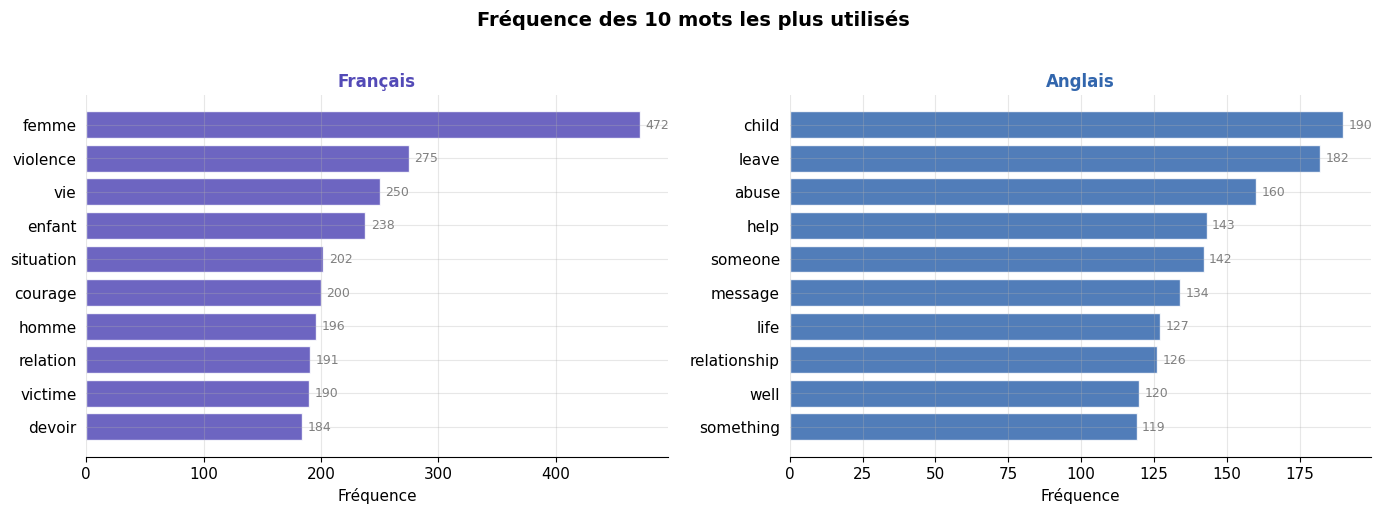

✅ Sauvegardé : viz1_frequence_mots.png


In [170]:
def top_mots(dataframe, n=10):
    """Retourne les n mots les plus fréquents d'un dataframe."""
    tous_les_mots = [
        mot
        for tokens in dataframe['lemmes_list'].dropna()
        for mot in tokens
        if len(mot) >= 3
    ]
    return Counter(tous_les_mots).most_common(n)

top_fr = top_mots(df_fr, n=10)
top_en = top_mots(df_en, n=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Fréquence des 10 mots les plus utilisés', fontsize=14, fontweight='bold', y=1.02)

for ax, top, couleur, titre in zip(
    axes,
    [top_fr, top_en],
    [COLORS['fr'], COLORS['en']],
    ['Français', 'Anglais']
):
    mots, freq = zip(*top)
    bars = ax.barh(mots[::-1], freq[::-1], color=couleur, alpha=0.85, edgecolor='white')
    ax.set_title(titre, fontsize=12, fontweight='bold', color=couleur)
    ax.set_xlabel('Fréquence')
    ax.bar_label(bars, padding=4, fontsize=9, color='gray')
    ax.spines['left'].set_visible(False)
    ax.tick_params(left=False)

plt.tight_layout()
plt.savefig('vizualisation/viz1_frequence_mots.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sauvegardé : viz1_frequence_mots.png')

---
## 😊😢 Visualisation 2 — Analyse de sentiments

⏳ Chargement du modèle de sentiment...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5153.75it/s]


⏳ Analyse des sentiments en cours...
✅ Analyse terminée


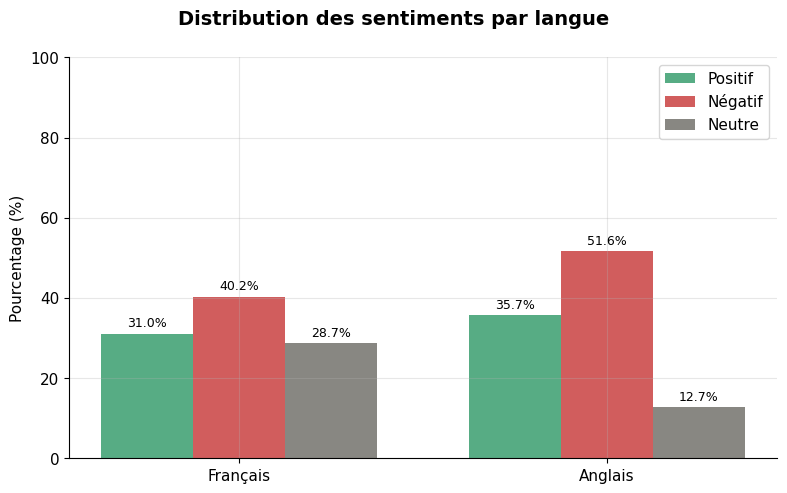

✅ Sauvegardé : viz2_sentiments.png


In [171]:
from transformers import pipeline

# Charger le modèle de sentiment multilingue
print('⏳ Chargement du modèle de sentiment...')
sentiment_model = pipeline(
    'sentiment-analysis',
    model='nlptown/bert-base-multilingual-uncased-sentiment',
    truncation=True,
    max_length=512
)

def analyser_sentiment(texte):
    """Retourne positif, négatif ou neutre selon le score."""
    if not isinstance(texte, str) or len(texte.strip()) < 5:
        return 'neutre'
    try:
        result = sentiment_model(texte[:512])[0]
        # Le modèle retourne 1-5 étoiles
        nb_etoiles = int(result['label'][0])
        if nb_etoiles <= 2:
            return 'négatif'
        elif nb_etoiles == 3:
            return 'neutre'
        else:
            return 'positif'
    except:
        return 'neutre'

# Appliquer sur un échantillon (les 300 premiers pour la rapidité)
print('⏳ Analyse des sentiments en cours...')
sample = df.sample(min(300, len(df)), random_state=42).copy()
sample['sentiment'] = sample['texte_nettoye'].apply(analyser_sentiment)
print('✅ Analyse terminée')

# Calcul des pourcentages par langue
sentiments_data = {}
for langue in ['français', 'anglais']:
    sub = sample[sample['langue'] == langue]['sentiment'].value_counts(normalize=True) * 100
    sentiments_data[langue] = {
        'positif' : round(sub.get('positif',  0), 1),
        'négatif' : round(sub.get('négatif',  0), 1),
        'neutre'  : round(sub.get('neutre',   0), 1)
    }

# Graphique
langues    = ['Français', 'Anglais']
positifs   = [sentiments_data['français']['positif'], sentiments_data['anglais']['positif']]
negatifs   = [sentiments_data['français']['négatif'], sentiments_data['anglais']['négatif']]
neutres    = [sentiments_data['français']['neutre'],  sentiments_data['anglais']['neutre']]

x     = np.arange(len(langues))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
fig.suptitle('Distribution des sentiments par langue', fontsize=14, fontweight='bold')

b1 = ax.bar(x - width, positifs, width, label='Positif', color=COLORS['positif'], alpha=0.85)
b2 = ax.bar(x,         negatifs, width, label='Négatif', color=COLORS['negatif'], alpha=0.85)
b3 = ax.bar(x + width, neutres,  width, label='Neutre',  color=COLORS['neutre'],  alpha=0.85)

ax.bar_label(b1, fmt='%.1f%%', padding=3, fontsize=9)
ax.bar_label(b2, fmt='%.1f%%', padding=3, fontsize=9)
ax.bar_label(b3, fmt='%.1f%%', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(langues)
ax.set_ylabel('Pourcentage (%)')
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()
plt.savefig('vizualisation/viz2_sentiments.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sauvegardé : viz2_sentiments.png')

---
## ☁️ Visualisation 3 — Nuage de mots (WordCloud)

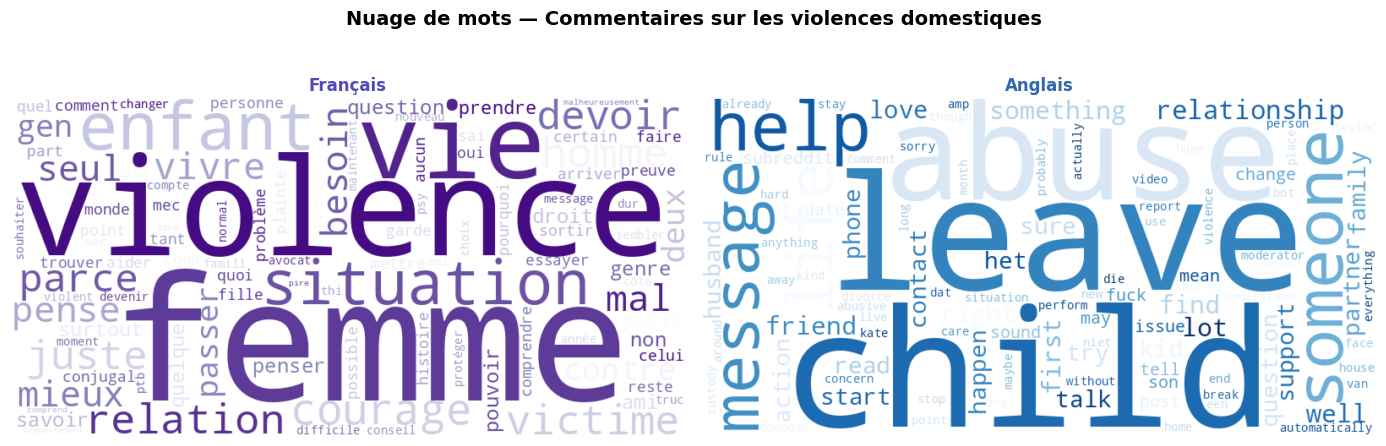

✅ Sauvegardé : viz3_wordcloud.png


In [172]:
def generer_wordcloud(dataframe, couleur, titre):
    """Génère un WordCloud à partir des lemmes."""
    tous_les_mots = ' '.join([
        mot
        for tokens in dataframe['lemmes_list'].dropna()
        for mot in tokens
        if len(mot) >= 3
    ])
    wc = WordCloud(
        width            = 800,
        height           = 400,
        background_color = 'white',
        colormap         = couleur,
        max_words        = 100,
        collocations     = False,
        contour_width    = 0
    ).generate(tous_les_mots)
    return wc

wc_fr = generer_wordcloud(df_fr, 'Purples', 'Français')
wc_en = generer_wordcloud(df_en, 'Blues',   'Anglais')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Nuage de mots — Commentaires sur les violences domestiques',
             fontsize=14, fontweight='bold')

for ax, wc, titre, couleur in zip(
    axes,
    [wc_fr, wc_en],
    ['Français', 'Anglais'],
    [COLORS['fr'], COLORS['en']]
):
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(titre, fontsize=12, fontweight='bold', color=couleur)

plt.tight_layout()
plt.savefig('vizualisation/viz3_wordcloud.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sauvegardé : viz3_wordcloud.png')

---
## 🗂️ Visualisation 4 — Topic Modeling (LDA)

⏳ Entraînement du modèle LDA...
✅ LDA entraîné


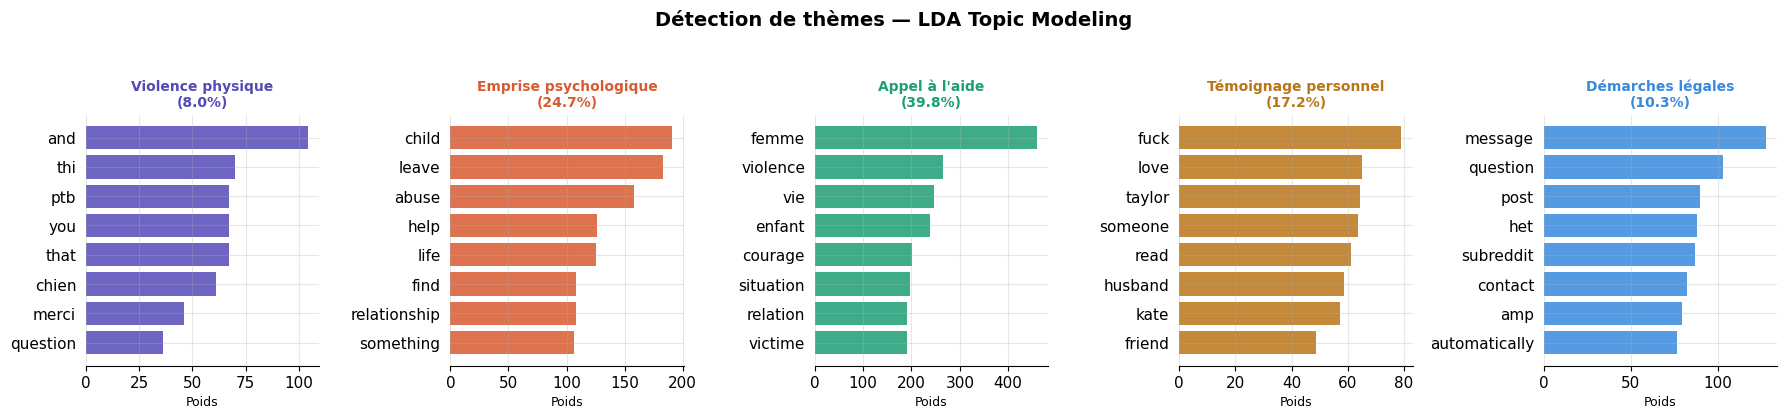

✅ Sauvegardé : viz4_lda_topics.png


In [173]:
N_TOPICS   = 5
N_TOP_MOTS = 8

NOMS_TOPICS = [
    'Violence physique',
    'Emprise psychologique',
    'Appel à l\'aide',
    'Témoignage personnel',
    'Démarches légales'
]

# Préparer le corpus (texte brut lemmatisé)
corpus = df['lemmes_str'].dropna().apply(lambda x: x.replace(' | ', ' '))

# Vectorisation
vectorizer = CountVectorizer(max_df=0.9, min_df=3, max_features=1000)
X          = vectorizer.fit_transform(corpus)
vocab      = vectorizer.get_feature_names_out()

# Entraînement LDA
print('⏳ Entraînement du modèle LDA...')
lda = LatentDirichletAllocation(
    n_components    = N_TOPICS,
    max_iter        = 20,
    random_state    = 42,
    learning_method = 'batch'
)
lda.fit(X)
print('✅ LDA entraîné')

# Extraire les top mots par topic
topics_mots = []
for i, topic in enumerate(lda.components_):
    top_idx  = topic.argsort()[-N_TOP_MOTS:][::-1]
    top_w    = [vocab[j] for j in top_idx]
    top_s    = [round(topic[j], 1) for j in top_idx]
    topics_mots.append((top_w, top_s))

# Calcul de la proportion de chaque topic
doc_topics  = lda.transform(X)
proportions = doc_topics.mean(axis=0) * 100

# Graphique : 5 sous-graphiques horizontaux
TOPIC_COLORS = ['#534AB7','#D85A30','#1D9E75','#BA7517','#378ADD']

fig, axes = plt.subplots(1, N_TOPICS, figsize=(18, 4))
fig.suptitle('Détection de thèmes — LDA Topic Modeling',
             fontsize=14, fontweight='bold', y=1.04)

for i, ax in enumerate(axes):
    mots, scores = topics_mots[i]
    ax.barh(mots[::-1], scores[::-1], color=TOPIC_COLORS[i], alpha=0.85)
    ax.set_title(
        f'{NOMS_TOPICS[i]}\n({proportions[i]:.1f}%)',
        fontsize=10, fontweight='bold', color=TOPIC_COLORS[i]
    )
    ax.spines['left'].set_visible(False)
    ax.tick_params(left=False)
    ax.set_xlabel('Poids', fontsize=9)

plt.tight_layout()
plt.savefig('vizualisation/viz4_lda_topics.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sauvegardé : viz4_lda_topics.png')

---
## 📅 Visualisation 5 — Évolution temporelle

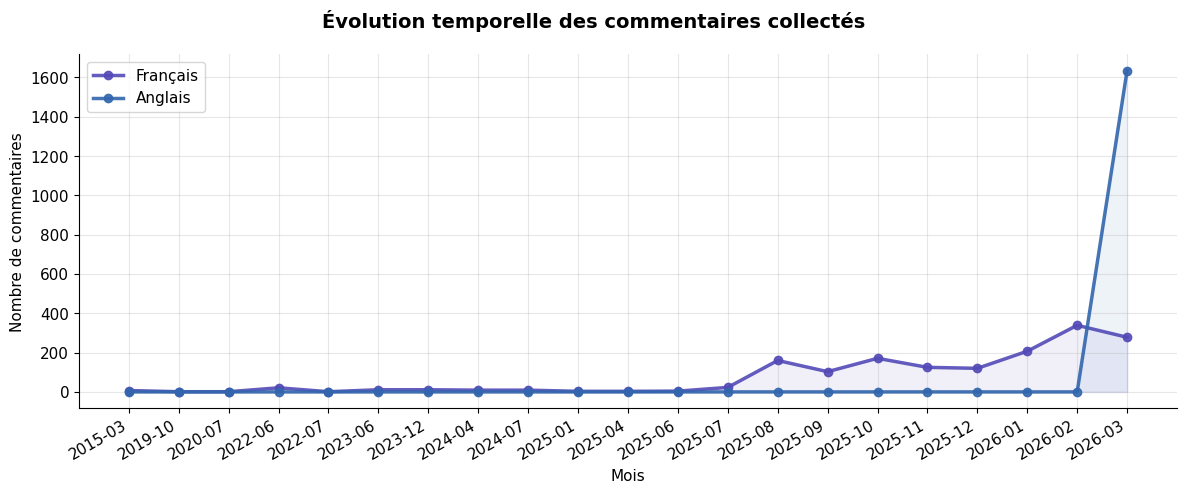

✅ Sauvegardé : viz5_evolution_temporelle.png


In [174]:
# Agréger par mois et par langue
df['mois'] = df['date'].dt.to_period('M')
temporel   = df.groupby(['mois', 'langue']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle('Évolution temporelle des commentaires collectés',
             fontsize=14, fontweight='bold')

for langue, couleur in [('français', COLORS['fr']), ('anglais', COLORS['en'])]:
    if langue in temporel.columns:
        ax.plot(
            temporel.index.astype(str),
            temporel[langue],
            marker   = 'o',
            color    = couleur,
            linewidth= 2.5,
            label    = langue.capitalize(),
            alpha    = 0.9
        )
        ax.fill_between(
            temporel.index.astype(str),
            temporel[langue],
            alpha = 0.08,
            color = couleur
        )

ax.set_xlabel('Mois')
ax.set_ylabel('Nombre de commentaires')
ax.legend()
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.savefig('vizualisation/viz5_evolution_temporelle.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sauvegardé : viz5_evolution_temporelle.png')